In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC  # Hoặc LinearSVC nếu data lớn
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from scipy.sparse import hstack  # Để concat sparse và dense nếu cần

In [ ]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [ ]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                               final  \
0  đánh giá: xuất_sắc ưu điểm: tốt về chất_lượng ...   
1  đánh giá: tiếc là đi vào ngày trời âm_u biển đ...   
2  đánh giá: xuất_sắc ưu điểm: phòng_ốc sạch_sẽ t...   
3  đánh giá: xuất_sắc ưu điểm: phòng sạch_sẽ gần ...   
4  đánh giá: hài_lòng ưu điểm: đối_diện biển rất ...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [ ]:
df.loc[:, 'label'] = df['score'].astype(int)
X = df['final']
y = df['label']

In [ ]:
from sklearn.model_selection import train_test_split

# Giả sử docs = df['final'] và labels = df['label']
docs = df['final']
labels = df['score'].astype(int)

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42,
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42,
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

# Định nghĩa Pipeline
model_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),          # giữ nguyên unigram + bigram
        max_features=5000,           # có thể tăng lên 8000–15000 nếu dữ liệu lớn
        min_df=3,                    # loại bỏ từ quá hiếm (tùy chọn)
        max_df=0.95                  # loại bỏ từ quá phổ biến (tùy chọn)
    )),
    ('knn', KNeighborsClassifier(
        n_neighbors=15,              # giá trị phổ biến: thử 7–31
        weights='distance',          # 'distance' thường tốt hơn 'uniform' cho text
        metric='cosine',             # rất phù hợp với TF-IDF vector (cosine similarity)
        algorithm='auto',            # hoặc 'brute' / 'ball_tree' tùy kích thước data
        n_jobs=-1                    # dùng tất cả core để predict nhanh hơn
    ))
])

In [ ]:
best_score = 0
best_params = {}

# Các giá trị cần thử (có thể mở rộng thêm)
for n_neighbors in [7, 11, 15, 21, 31]:
    for weights in ['uniform', 'distance']:
        # Cập nhật tham số cho KNN
        model_pipeline.set_params(
            knn__n_neighbors=n_neighbors,
            knn__weights=weights
        )

        # Train trên train set
        model_pipeline.fit(X_train, y_train)

        # Đánh giá trên validation set
        val_score = model_pipeline.score(X_val, y_val)
        print(f"n_neighbors={n_neighbors}, weights={weights} => Validation Accuracy: {val_score:.4f}")

        if val_score > best_score:
            best_score = val_score
            best_params = {
                'n_neighbors': n_neighbors,
                'weights': weights
            }

print(f"---")
print(f"Tham số tốt nhất tìm được: {best_params}")
print(f"Validation Accuracy tốt nhất: {best_score:.4f}")

# Fit lại với tham số tốt nhất (có thể concat train + val để tăng data)
model_pipeline.set_params(
    knn__n_neighbors=best_params['n_neighbors'],
    knn__weights=best_params['weights']
)
model_pipeline.fit(X_train, y_train)  # hoặc pd.concat([X_train, X_val]), pd.concat([y_train, y_val])

# Đánh giá cuối cùng trên test set
print(f"Final Test Accuracy: {model_pipeline.score(X_test, y_test):.4f}")

n_neighbors=7, weights=uniform => Validation Accuracy: 0.6885
n_neighbors=7, weights=distance => Validation Accuracy: 0.6905
n_neighbors=11, weights=uniform => Validation Accuracy: 0.7027
n_neighbors=11, weights=distance => Validation Accuracy: 0.6982
n_neighbors=15, weights=uniform => Validation Accuracy: 0.7108
n_neighbors=15, weights=distance => Validation Accuracy: 0.7097
n_neighbors=21, weights=uniform => Validation Accuracy: 0.7215
n_neighbors=21, weights=distance => Validation Accuracy: 0.7156
n_neighbors=31, weights=uniform => Validation Accuracy: 0.7178
n_neighbors=31, weights=distance => Validation Accuracy: 0.7180
---
Tham số tốt nhất tìm được: {'n_neighbors': 21, 'weights': 'uniform'}
Validation Accuracy tốt nhất: 0.7215
Final Test Accuracy: 0.7105


In [ ]:
y_pred = model_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           5       0.66      0.55      0.60       194
           6       0.78      0.26      0.39       212
           7       0.50      0.15      0.23       483
           8       0.56      0.45      0.50      1107
           9       0.82      0.43      0.56      1712
          10       0.72      0.97      0.83      4520

    accuracy                           0.71      8228
   macro avg       0.67      0.47      0.52      8228
weighted avg       0.71      0.71      0.68      8228



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import torch
import textwrap   # để in đẹp hơn nếu cần

# ----------------------------------------------------------------------
# Đảm bảo y_test và y_pred ở dạng numpy array (phổ biến nhất)
# ----------------------------------------------------------------------
if isinstance(y_test, torch.Tensor):
    y_test_np    = y_test.cpu().numpy()
else:
    y_test_np    = np.asarray(y_test)

if isinstance(y_pred, torch.Tensor):
    y_pred_np    = y_pred.cpu().numpy()
else:
    y_pred_np    = np.asarray(y_pred)

# Nếu là multi-class và y_pred là probability → lấy argmax
if len(y_pred_np.shape) > 1 and y_pred_np.shape[1] > 1:
    y_pred_np = np.argmax(y_pred_np, axis=1)

# ----------------------------------------------------------------------
# Tính các metric cơ bản
# ----------------------------------------------------------------------
accuracy = accuracy_score(y_test_np, y_pred_np)

# In header
print("\n" + "="*80)
print("              MODEL EVALUATION ON TEST SET")
print("="*80)

# Accuracy chi tiết
print(f"\nOverall Accuracy:")
print(f"  • {accuracy:.4f}  ({accuracy*100:.2f}%)")
print("-"*60)

# Classification Report (chi tiết, 4 chữ số thập phân)
print("\nClassification Report:")
print(classification_report(
    y_test_np,
    y_pred_np,
    digits=4,
    zero_division=0,
    target_names=[str(c) for c in model_pipeline.classes_]   # nếu có class names đẹp
    # target_names = ['Negative', 'Positive']  # → bạn có thể hard-code tên lớp nếu muốn
))

# ----------------------------------------------------------------------
# Confusion Matrix - cả dạng số lượng và dạng chuẩn hóa (%)
# ----------------------------------------------------------------------
cm = confusion_matrix(y_test_np, y_pred_np)

print("\nConfusion Matrix (Raw counts):")
print(cm)

# Chuẩn hóa theo hàng (precision-oriented: tỷ lệ dự đoán đúng trong mỗi lớp thật)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)  # tránh NaN nếu có lớp không có mẫu

# ----------------------------------------------------------------------
# Một số metric tổng hợp bổ sung (macro / weighted)
# ----------------------------------------------------------------------
print("\nSummary Metrics:")
print(f"  Macro    Avg Precision : {precision_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg Recall    : {recall_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Macro    Avg F1-score  : {f1_score(y_test_np, y_pred_np, average='macro', zero_division=0):.4f}")
print(f"  Weighted Avg F1-score : {f1_score(y_test_np, y_pred_np, average='weighted', zero_division=0):.4f}")

# Kết thúc đẹp
# ----------------------------------------------------------------------
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*80)
print(f"HOÀN TẤT ĐÁNH GIÁ!  •  Accuracy = {accuracy*100:.2f}%")
print("="*80 + "\n")


              MODEL EVALUATION ON TEST SET

Overall Accuracy:
  • 0.7105  (71.05%)
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           5     0.6605    0.5515    0.6011       194
           6     0.7778    0.2642    0.3944       212
           7     0.4965    0.1470    0.2268       483
           8     0.5636    0.4526    0.5020      1107
           9     0.8200    0.4258    0.5606      1712
          10     0.7216    0.9695    0.8273      4520

    accuracy                         0.7105      8228
   macro avg     0.6733    0.4684    0.5187      8228
weighted avg     0.7076    0.7105    0.6763      8228


Confusion Matrix (Raw counts):
[[ 107    3   18   22    7   37]
 [  18   56   14   38   15   71]
 [  17    5   71  131   45  214]
 [  10    5   18  501   44  529]
 [   7    1   12  123  729  840]
 [   3    2   10   74   49 4382]]

Summary Metrics:
  Macro    Avg Precision : 0.6733
  Mac

In [ ]:
import joblib
import os
from datetime import datetime

# Thư mục lưu mô hình cho KNN
save_dir = '/content/drive/MyDrive/Bert/Model/tf-idf-knn'
os.makedirs(save_dir, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
base_name = f'sentiment_model_{timestamp}'

# Lưu riêng vectorizer
vectorizer_filename = os.path.join(save_dir, f'{base_name}_tfidf_vectorizer.pkl')
joblib.dump(model_pipeline.named_steps['tfidf'], vectorizer_filename)

# Lưu riêng classifier (KNN)
classifier_filename = os.path.join(save_dir, f'{base_name}_knn_classifier.pkl')
joblib.dump(model_pipeline.named_steps['knn'], classifier_filename)

# Lưu toàn bộ pipeline (khuyến nghị dùng cái này để deploy/inference nhanh)
pipeline_filename = os.path.join(save_dir, f'{base_name}_full_pipeline.pkl')
joblib.dump(model_pipeline, pipeline_filename)

print("Đã lưu 3 file cho mô hình TF-IDF + KNN:")
print(f"1. Vectorizer:     {vectorizer_filename}")
print(f"2. KNN Classifier: {classifier_filename}")
print(f"3. Full Pipeline:  {pipeline_filename}")

Đã lưu 3 file cho mô hình TF-IDF + KNN:
1. Vectorizer:     /content/drive/MyDrive/Bert/Model/tf-idf-knn/sentiment_model_20260317_172143_tfidf_vectorizer.pkl
2. KNN Classifier: /content/drive/MyDrive/Bert/Model/tf-idf-knn/sentiment_model_20260317_172143_knn_classifier.pkl
3. Full Pipeline:  /content/drive/MyDrive/Bert/Model/tf-idf-knn/sentiment_model_20260317_172143_full_pipeline.pkl


In [ ]:
import joblib

# Đường dẫn file full pipeline (thay bằng đường dẫn thực tế của bạn sau khi lưu)
model_filename = '/content/drive/MyDrive/Bert/Model/tf-idf-knn/sentiment_model_20260310_153251_full_pipeline.pkl'
# Ví dụ: dùng đường dẫn mới nhất bạn vừa lưu

loaded_model = joblib.load(model_filename)

print("Đã load thành công mô hình TF-IDF + KNN")

# Test nhanh trên vài mẫu (giả sử bạn có X_test, y_test)
try:
    test_accuracy = loaded_model.score(X_test[:100], y_test[:100])
    print(f"Accuracy trên 100 mẫu test sau khi load: {test_accuracy:.4f}")
except NameError:
    print("Chưa định nghĩa X_test / y_test → bỏ qua phần score")

# Predict một câu ví dụ
sample_text = ["Sản phẩm rất tốt, giao hàng nhanh, sẽ mua tiếp!"]

pred = loaded_model.predict(sample_text)

print(f"Dự đoán nhãn: {pred[0]}")



Đã load thành công mô hình TF-IDF + KNN
Accuracy trên 100 mẫu test sau khi load: 0.6500
Dự đoán nhãn: 10


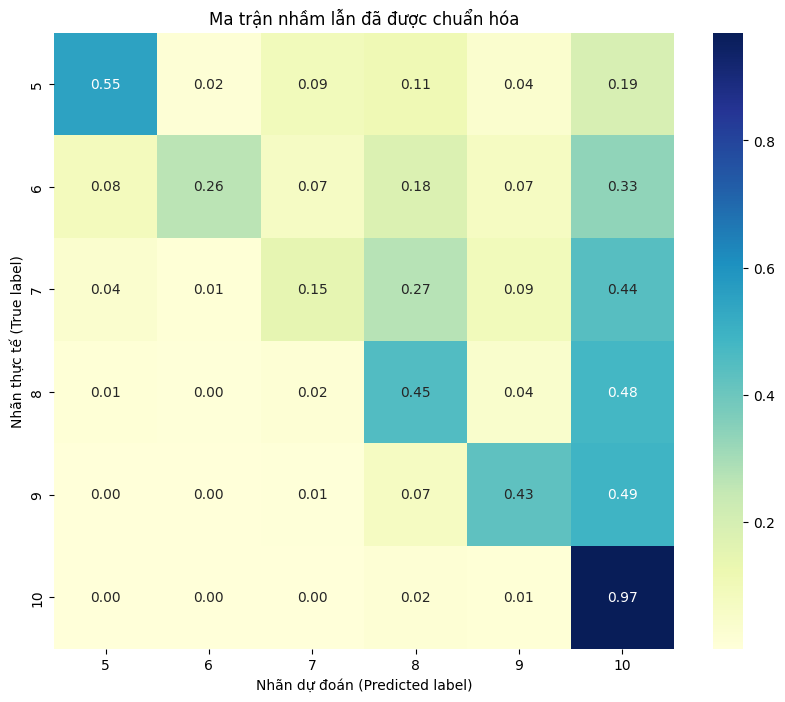

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns   # chỉ cần nếu bạn muốn dùng seaborn ở phần sau


y_pred = model_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)

cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Lấy tên các lớp dựa trên điểm rating thực tế
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='YlGnBu',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Ma trận nhầm lẫn đã được chuẩn hóa')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()


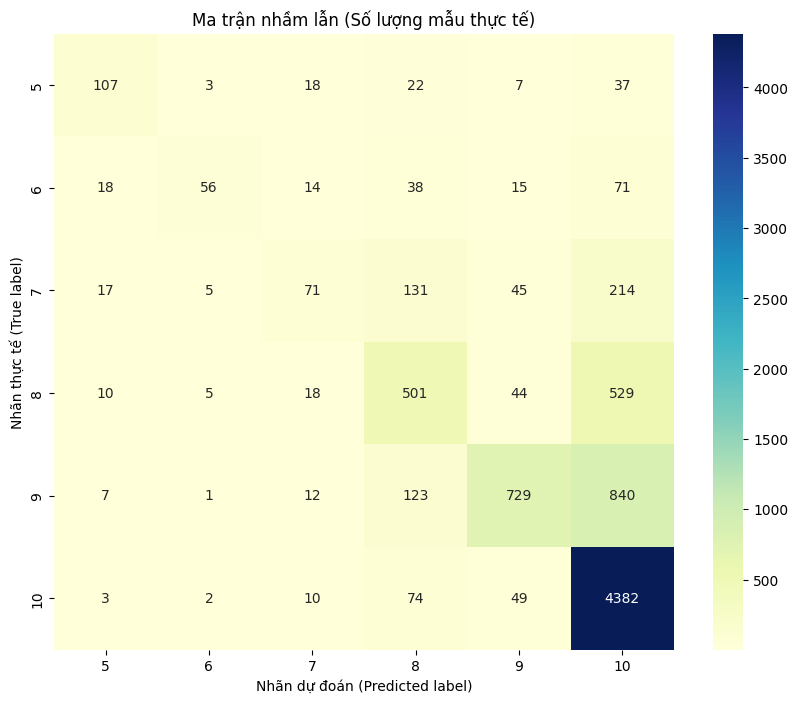

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Tính ma trận nhầm lẫn (đây là dạng số lượng gốc)
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
# 2. Tên các lớp (từ 5 đến 10)
class_names = [str(i) for i in range(5, 11)]

plt.figure(figsize=(10, 8))

# 3. Vẽ Heatmap với biến 'cm' gốc
sns.heatmap(
    cm,
    annot=True,      # Hiển thị số lên ô
    fmt='d',         # ĐỊNH DẠNG LÀ SỐ NGUYÊN (d = decimal/integer)
    cmap='YlGnBu',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Ma trận nhầm lẫn (Số lượng mẫu thực tế)')
plt.ylabel('Nhãn thực tế (True label)')
plt.xlabel('Nhãn dự đoán (Predicted label)')
plt.show()